# Building Age Classification from Satellite Imagery

# Notebook 3 — Feature Engineering & Preprocessing

---

This notebook transforms the raw wide-format Landsat parquet files into per-pixel feature vectors
suitable for machine learning.

**City roles**

| City | Role |
|------|------|
| **Madrid** | Labelled training city — used for cross-validation and model training in Notebook 4 |
| **Amsterdam** | Transfer target — a few labelled examples are used for few-shot adaptation in Notebook 4 |

**Key design choice: one row per pixel, not per observation**

The raw data contains one row per *(pixel, year)* pair — a pixel observed for 40 years contributes 40 rows.
Feeding raw per-year rows to a classifier treats each year as an independent sample and leaks
temporal structure. Instead we collapse each pixel's full time series into a single feature vector
of temporal statistics. This forces the model to reason about *trends and variability over time*,
which is exactly what distinguishes age classes.

** NOTE**:  these are only **suggestions** for feature processing. iIn your own code, you may decide to use different features.  "The proof of the puddign is in the eating"--in the end it is the _predictive performance_ that determines whether or not a feature set is good.

## 3.1 Setup & Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# ── Constants ─────────────────────────────────────────────────────────────────
BASE_BANDS   = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
INDEX_COLS   = ['NDVI', 'NDBI', 'UI', 'MNDWI', 'BSI',          # original five
                'NBR', 'NDWI', 'EVI', 'SAVI',                   # additional indices
                'tc_brightness', 'tc_greenness', 'tc_wetness',  # tasseled-cap-like
                'r_SWIR1_NIR', 'r_SWIR2_SWIR1']                 # simple band ratios
BLUE_MAX     = 15_000   # atmospheric outlier threshold — see Notebook 2

CLASS_EVENTS = {'Amsterdam': 1945, 'Madrid': 1960}
CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CLASS_LABELS = {
    'Amsterdam': {1: 'Pre-1945',  2: '1945-1984', 3: '1984-2004', 4: '2004-2024'},
    'Madrid':    {1: 'Pre-1960',  2: '1960-1984', 3: '1984-2004', 4: '2004-2024'},
}

plt.rcParams['figure.dpi'] = 100
print("Setup complete.")

---

## 3.2 Load the Data

Each file is one city's complete time series in wide format: one row per *(pixel, year)*,
with up to three Landsat observations stored side-by-side as `Blue_1 / Blue_2 / Blue_3`, etc.
The `qa_valid_N` flags indicate which observations passed the cloud/shadow quality filter.

In [2]:
DATA_DIR = 'data'

df_madrid    = pd.read_parquet(f'{DATA_DIR}/madrid_train.parquet')
df_amsterdam = pd.read_parquet(f'{DATA_DIR}/amsterdam_data.parquet')

for name, df in [('Madrid', df_madrid), ('Amsterdam', df_amsterdam)]:
    print(f'{name}: {df.shape[0]:,} rows x {df.shape[1]} columns')
    print(f'  Years:  {df["year"].min()}-{df["year"].max()}  ({df["year"].nunique()} distinct years)')
    print(f'  Pixels: {df.groupby(["px_key","py_key"]).ngroups:,} unique geographic pixels')
    print()


Madrid: 3,172,765 rows x 48 columns
  Years:  1984-2025  (42 distinct years)
  Pixels: 76,263 unique geographic pixels

Amsterdam: 1,062,877 rows x 48 columns
  Years:  1984-2025  (42 distinct years)
  Pixels: 25,992 unique geographic pixels



---

## 3.3 Assign Age Classes

`weighted_mean_year` is the BAG-weighted estimated construction year for each pixel.
We cut it into four ordered age classes using city-specific boundaries identified in Notebook 1.

| Class | Madrid | Amsterdam |
|-------|--------|-----------|
| 1 | Pre-1960 | Pre-1945 |
| 2 | 1960-1984 | 1945-1984 |
| 3 | 1984-2004 | 1984-2004 |
| 4 | 2004-2024 | 2004-2024 |

Classes 3 and 4 fall entirely within the Landsat observation record (1984-present),
so the spectral signature around the construction year may be directly visible in the time series.

In [3]:
def assign_age_class(data, events=CLASS_EVENTS):
    out = data.copy()
    out['age_class'] = pd.NA
    for city, ev in events.items():
        mask = out['city'] == city
        if mask.any():
            bins = [-np.inf, ev, 1984, 2004, np.inf]
            out.loc[mask, 'age_class'] = pd.cut(
                out.loc[mask, 'weighted_mean_year'],
                bins=bins, labels=[1, 2, 3, 4]
            ).astype('Int64')
    return out

df_madrid    = assign_age_class(df_madrid)
df_amsterdam = assign_age_class(df_amsterdam)

for name, df in [('Madrid', df_madrid), ('Amsterdam', df_amsterdam)]:
    labels = CLASS_LABELS[name]
    pixels = df.drop_duplicates(['px_key', 'py_key'])
    print(f'{name} ({pixels["age_class"].notna().sum():,} labelled pixels):')
    for cls in [1, 2, 3, 4]:
        n = (pixels['age_class'] == cls).sum()
        print(f'  Class {cls} ({labels[int(cls)]}): {n:,}')
    print()


Madrid (76,263 labelled pixels):
  Class 1 (Pre-1960): 13,794
  Class 2 (1960-1984): 27,152
  Class 3 (1984-2004): 18,672
  Class 4 (2004-2024): 16,645

Amsterdam (25,992 labelled pixels):
  Class 1 (Pre-1945): 7,568
  Class 2 (1945-1984): 8,802
  Class 3 (1984-2004): 6,745
  Class 4 (2004-2024): 2,877



---

## 3.4 Flatten to One Best Observation Per Year

Each row currently stores up to three observations sorted by day-of-year.
`make_flat_view()` picks the first QA-valid observation for each band, then discards rows
where no valid observation exists for any band.

**Atmospheric outlier removal:** Landsat 7 scenes in Amsterdam contain haze not caught
by the standard QA flags. Blue reflectance > 15,000 reliably identifies these contaminated
observations (normal urban Blue peaks around 10,000). These rows are removed before
any feature computation.

In [ ]:
def get_best_obs_band(data, band):
    col = np.full(len(data), np.nan)
    for slot in [1, 2, 3]:
        bc = f'{band}_{slot}'
        qc = f'qa_valid_{slot}'
        if bc not in data.columns or qc not in data.columns:
            continue
        valid = data[qc].fillna(False).values
        col = np.where(np.isnan(col) & valid, data[bc].fillna(np.nan).values, col)
    return col

def make_flat_view(data):
    keep = [c for c in ['pixel_id', 'city', 'year', 'px_key', 'py_key',
                        'row', 'col', 'coverage',
                        'weighted_mean_year', 'age_class']
            if c in data.columns]
    out = data[keep].copy()
    for band in BASE_BANDS:
        out[band] = get_best_obs_band(data, band)
    out = out.dropna(subset=BASE_BANDS)
    n_before = len(out)
    out = out[out['Blue'] <= BLUE_MAX].copy()
    removed = n_before - len(out)
    if removed:
        city = data['city'].iloc[0] if 'city' in data.columns else ''
        print(f'  [{city}] Removed {removed:,} haze-contaminated rows (Blue > {BLUE_MAX:,})')
    return out

print('Flattening observations...')
flat_madrid    = make_flat_view(df_madrid)
flat_amsterdam = make_flat_view(df_amsterdam)

for name, flat in [('Madrid', flat_madrid), ('Amsterdam', flat_amsterdam)]:
    n_pix = flat.groupby(['px_key', 'py_key']).ngroups
    print(f'{name}: {len(flat):,} valid pixel-year rows, {n_pix:,} unique pixels')

# ── Period coverage indicators ─────────────────────────────────────────────────
# Computed NOW, before gap-filling, while the original observed-year pattern is intact.
EARLY_CUTOFF = 2003   # 1984-2003: first ~20 years of Landsat record
LATE_START   = 2004   # 2004+:     most recent ~20 years
PID          = ['px_key', 'py_key']

def period_coverage(flat):
    pixels    = flat[PID].drop_duplicates()
    has_early = flat[flat['year'] <= EARLY_CUTOFF].drop_duplicates(PID).assign(has_early_data=1.0)
    has_late  = flat[flat['year'] >= LATE_START].drop_duplicates(PID).assign(has_late_data=1.0)
    ind = (pixels
           .merge(has_early[PID + ['has_early_data']], on=PID, how='left')
           .merge(has_late[PID  + ['has_late_data']],  on=PID, how='left')
           .fillna(0.0))
    return ind

indicators_madrid    = period_coverage(flat_madrid)
indicators_amsterdam = period_coverage(flat_amsterdam)

for name, ind in [('Madrid', indicators_madrid), ('Amsterdam', indicators_amsterdam)]:
    print(f'{name}: {(ind["has_early_data"]==0).sum()} pixels with no early data, '
          f'{(ind["has_late_data"]==0).sum()} with no late data')


---

## 3.5 Time-Series Gap Filling

The observed flat data is sparse: each pixel has one row per year for which a cloud-free
Landsat scene was available — typically 30-40 of the 41 possible years. It does not cover
every year uniformly, and individual years are sometimes missing due to cloud cover or
scene selection.

We extend each pixel to a complete annual time series (one row per year from the first
to the last available year across all pixels):

- **Interior gaps** — years between two observed years: **linear interpolation**.
- **Before first observation**: backward-fill with the first observed value.
- **After last observation**: forward-fill with the last observed value.

After gap-filling, every pixel has a value for every year. Early- and late-period statistics
computed in the next section are therefore always defined, and no imputation step is needed.

> **Note:** All pixels have Landsat observations both before and after 2004 — the satellite
> has been recording every location since 1984 regardless of what building currently stands
> there. A Class 4 pixel (current building constructed after 2004) does have pre-2004
> observations; they show whatever occupied that location previously — an older building
> that was demolished, vacant land, or a construction site. The  /
>  indicators flag the rare cases where a pixel has no valid scenes at all
> in a period (e.g., due to persistent cloud cover in that location).

In [ ]:
def fill_time_series_gaps(flat):
    year_min = flat['year'].min()
    year_max = flat['year'].max()
    all_years = list(range(year_min, year_max + 1))

    # Build complete (pixel x year) grid, inheriting constant per-pixel metadata
    pixels = flat[PID + ['city', 'coverage', 'row', 'col',
                         'weighted_mean_year', 'age_class']].drop_duplicates(PID)
    grid   = pixels.assign(_k=1).merge(
        pd.DataFrame({'year': all_years, '_k': 1}), on='_k'
    ).drop('_k', axis=1)

    # Merge in observed band values (NaN where year not observed)
    merged = grid.merge(flat[PID + ['year'] + BASE_BANDS], on=PID + ['year'], how='left')
    merged = merged.sort_values(PID + ['year'])

    def interp(s):
        s = s.interpolate(method='linear')   # interior gaps: linear
        return s.bfill().ffill()             # edges: nearest observed value

    for band in BASE_BANDS:
        merged[band] = merged.groupby(PID)[band].transform(interp)

    return merged

print('Filling time-series gaps...')
flat_madrid    = fill_time_series_gaps(flat_madrid)
flat_amsterdam = fill_time_series_gaps(flat_amsterdam)

for name, flat in [('Madrid', flat_madrid), ('Amsterdam', flat_amsterdam)]:
    n_pix = flat.groupby(PID).ngroups
    print(f'{name}: {len(flat):,} rows after gap-fill '
          f'({flat["year"].nunique()} years x {n_pix:,} pixels)')


---

## 3.5 Spectral Indices & Band Algebra

Normalised band ratios are less sensitive to illumination differences between scenes and
sensors, and highlight specific surface properties.

| Index | Formula | What it captures |
|-------|---------|-----------------|
| NDVI | (NIR - Red) / (NIR + Red) | Vegetation — low values indicate built-up surfaces |
| NDBI | (SWIR1 - NIR) / (SWIR1 + NIR) | Built-up intensity |
| UI | (SWIR2 - NIR) / (SWIR2 + NIR) | Urban areas |
| MNDWI | (Green - SWIR1) / (Green + SWIR1) | Water; negative for built-up land |
| BSI | ((SWIR1+Red)-(NIR+Blue)) / ((SWIR1+Red)+(NIR+Blue)) | Bare soil vs vegetated |
| NBR | (NIR - SWIR2) / (NIR + SWIR2) | Burn/bare surface index; low for built-up |
| NDWI | (Green - NIR) / (Green + NIR) | Water index; negative for urban surfaces |
| EVI | 2.5 (NIR-Red) / (NIR + 6 Red - 7.5 Blue) | Enhanced vegetation, less soil-biased than NDVI |
| SAVI | 1.5 (NIR-Red) / (NIR + Red + L) | Vegetation with soil-brightness correction (L = 0.5) |
| tc_brightness / tc_greenness / tc_wetness | Crist (1985) tasseled-cap linear combos of the 6 bands | Overall brightness, canopy signal, moisture |
| r_SWIR1_NIR, r_SWIR2_SWIR1 | SWIR1/NIR, SWIR2/SWIR1 | Moisture / mineralogy ratios sensitive to materials |

These are computed per year on the gap-filled series (cell 12) and then aggregated into
temporal statistics in the next section. All are dimensionless or on the harmonised
reflectance scale, which keeps them comparable across the two cities.

In [ ]:
def compute_spectral_indices(df):
    df = df.copy()
    B, G, R = df['Blue'], df['Green'], df['Red']
    N, S1, S2 = df['NIR'], df['SWIR1'], df['SWIR2']
    eps = 1e-6
    # ── Original five ────────────────────────────────────────────────────────
    df['NDVI']  = (N - R)  / (N + R  + eps)
    df['NDBI']  = (S1 - N) / (S1 + N + eps)
    df['UI']    = (S2 - N) / (S2 + N + eps)
    df['MNDWI'] = (G - S1) / (G + S1 + eps)
    df['BSI']   = ((S1 + R) - (N + B)) / ((S1 + R) + (N + B) + eps)
    # ── Additional indices ───────────────────────────────────────────────────
    df['NBR']   = (N - S2) / (N + S2 + eps)
    df['NDWI']  = (G - N)  / (G + N  + eps)
    df['EVI']   = 2.5 * (N - R) / (N + 6.0 * R - 7.5 * B + eps)
    # SAVI soil-adjustment constant L = 0.5 in reflectance units (= 5000 here)
    df['SAVI']  = 1.5 * (N - R) / (N + R + 5_000.0 + eps)
    # ── Tasseled-cap-like linear combinations (Crist 1985 TM coefficients) ───
    df['tc_brightness'] = ( 0.3037 * B + 0.2793 * G + 0.4743 * R
                          + 0.5585 * N + 0.5082 * S1 + 0.1863 * S2)
    df['tc_greenness']  = (-0.2848 * B - 0.2435 * G - 0.5436 * R
                          + 0.8469 * N + 0.3127 * S1 - 0.1805 * S2)
    df['tc_wetness']    = ( 0.1509 * B + 0.1973 * G + 0.3279 * R
                          + 0.3406 * N - 0.7112 * S1 - 0.4559 * S2)
    # ── Simple band ratios ───────────────────────────────────────────────────
    df['r_SWIR1_NIR']   = S1 / (N + eps)
    df['r_SWIR2_SWIR1'] = S2 / (S1 + eps)
    return df

flat_madrid    = compute_spectral_indices(flat_madrid)
flat_amsterdam = compute_spectral_indices(flat_amsterdam)

print(f'Spectral indices added: {len(INDEX_COLS)} total.')
flat_madrid[INDEX_COLS].describe().round(4)

---

## 3.6 Per-Pixel Temporal Feature Engineering

This is the most important section. Each pixel's time series — up to 40 annual observations —
is collapsed into a fixed-length feature vector. The goal is to capture *how the spectral
signature changes over time*, not just what it looks like at a single moment.

### Feature groups

| Group | Features | Count |
|-------|----------|-------|
| Overall mean/std, 6 bands |  | 12 |
| Overall mean/std, 14 indices & band-algebra terms |  | 28 |
| Early-period mean/std (1984-2003) | bands + indices | 40 |
| Late-period mean/std (2004+) | bands + indices | 40 |
| Year-on-year change mean/std | 6 bands | 12 |
| Early→late deltas & percent changes | `{c}_late - {c}_early` | 40 |
| Spectral interaction terms | `NDBI-NDVI`, `UI-MNDWI`, ratios | 4 |
| Building coverage |  | 1 |
| Period coverage indicator | `has_early_data`, `has_late_data` | 2 |
| Regional: 3×3 neighbourhood | `n_neighbours`, neighbour mean/std, local contrast | 32 |
| Regional: tile aggregates | 20×20 (600 m) and 50×50 (1.5 km) tile mean/std/deviation | 62 |
| **Total** | | **273** |

**Why split at 2004?** The 1984-2003 window shows the *pre-existing* land use at each
location, while 2004+ shows the *current* building's spectral signature. For Classes 1
and 2 (pre-1984 buildings) the split falls entirely within the building's lifetime, so
both periods reflect the same structure and the signals should be stable. For Class 3
(built 1984-2004) the construction event falls somewhere in the early period, and for
Class 4 (built after 2004) the early period captures what was demolished or replaced —
an older building, a field, or a construction site. The contrast between early and late
statistics should therefore be largest and most class-discriminative for Classes 3 and 4.

**Why year-on-year change?** As seen in Notebook 2, the std of annual change separates
pre-satellite-era buildings (Classes 1 & 2, narrow YOY distribution) from those built during
the record (Classes 3 & 4, broader distribution). This is a direct time-series signal.

**Why regional features?** Notebook 2 measured strong spatial autocorrelation (corr between
a pixel's mean Blue and its 8-neighbour mean is 0.76 vs 0.19 for a shuffled null) and
neighbouring pixels share the age class more often than chance. Neighbourhood and tile
statistics therefore add genuine information. Only *features* are ever aggregated — never
`age_class` or `weighted_mean_year`, which are not observable for unlabelled pixels in a
new city.

In [ ]:
def build_pixel_features(flat):
    s = flat[flat['age_class'].notna()].copy()
    s = s.sort_values(PID + ['year'])
    stat_cols = BASE_BANDS + INDEX_COLS

    # ── Overall stats: bands + indices ────────────────────────────────────────
    grp = s.groupby(PID + ['age_class'])
    overall = pd.concat([
        grp[stat_cols].mean().add_suffix('_mean'),
        grp[stat_cols].std().add_suffix('_std'),
    ], axis=1).reset_index()
    overall['age_class'] = overall['age_class'].astype(int)

    # ── Early-period stats (1984-2003), bands + indices ───────────────────────
    early_grp = s[s['year'] <= EARLY_CUTOFF].groupby(PID)
    early = pd.concat([
        early_grp[stat_cols].mean().add_suffix('_early_mean'),
        early_grp[stat_cols].std().add_suffix('_early_std'),
    ], axis=1).reset_index()

    # ── Late-period stats (2004+), bands + indices ────────────────────────────
    late_grp = s[s['year'] >= LATE_START].groupby(PID)
    late = pd.concat([
        late_grp[stat_cols].mean().add_suffix('_late_mean'),
        late_grp[stat_cols].std().add_suffix('_late_std'),
    ], axis=1).reset_index()

    # ── Year-on-year change stats ─────────────────────────────────────────────
    for b in BASE_BANDS:
        s[f'd_{b}'] = s.groupby(PID)[b].diff()
    dcols = [f'd_{b}' for b in BASE_BANDS]
    diff_grp = s.groupby(PID)[dcols]
    diff = pd.concat([
        diff_grp.mean().add_suffix('_mean'),
        diff_grp.std().add_suffix('_std'),
    ], axis=1).reset_index()

    # ── Per-pixel metadata (spatial position + coverage; row/col are used only
    #    to build regional features and are never model inputs themselves) ─────
    meta = s.groupby(PID)[['row', 'col', 'coverage']].first().reset_index()

    result = overall
    for extra in [early, late, diff, meta]:
        result = result.merge(extra, on=PID, how='left')

    # ── Early→late temporal deltas (construction-era shifts) ──────────────────
    for c in stat_cols:
        result[f'{c}_delta'] = result[f'{c}_late_mean'] - result[f'{c}_early_mean']
        result[f'{c}_pct']   = result[f'{c}_delta'] / (result[f'{c}_early_mean'].abs() + 1e-3)

    # ── Spectral interaction terms (guarded denominators) ─────────────────────
    eps = 1e-3
    result['NDBI_minus_NDVI'] = result['NDBI_mean'] - result['NDVI_mean']
    result['NDBI_NDVI_ratio'] = (result['NDBI_mean'] + eps) / (result['NDVI_mean'].abs() + eps)
    result['UI_MNDWI_diff']   = result['UI_mean'] - result['MNDWI_mean']
    result['BSI_NDBI_ratio']  = (result['BSI_mean'] + eps) / (result['NDBI_mean'].abs() + eps)
    return result

print('Building per-pixel feature vectors...')
features_madrid    = build_pixel_features(flat_madrid)
features_amsterdam = build_pixel_features(flat_amsterdam)

# ── Merge period indicators ───────────────────────────────────────────────────
features_madrid    = features_madrid.merge(indicators_madrid,    on=PID, how='left')
features_amsterdam = features_amsterdam.merge(indicators_amsterdam, on=PID, how='left')

for name, feat in [('Madrid', features_madrid), ('Amsterdam', features_amsterdam)]:
    print(f'{name}: {len(feat):,} pixels, {feat.shape[1]} total columns'
          f'  (has_early_data=0: {(feat["has_early_data"]==0).sum():,})')

---

## 3.6b Regional (Spatial Neighbourhood) Features

Urban fabric is contiguous: pixels near each other share construction era, materials and
microclimate. Notebook 2 confirmed this — the correlation between a pixel's mean Blue and
its 8-neighbour mean is **0.76** (shuffled null: 0.19), and 33% of neighbours share an age
class vs 27% expected by chance.

Three groups are added on the integer `(row, col)` grid (1 cell = 30 m):

| Group | Scale | Features |
|-------|-------|----------|
| R1 neighbourhood | 3×3 (90 m) | `n_neighbours`, neighbour mean & std, **own − neighbour mean** for 10 key features |
| R3 density context | 3×3 | `neigh_frac` (fraction of the 8 cells that exist), neighbour `coverage` stats (in R1 set) |
| R4 tile aggregates | 20×20 (600 m), 50×50 (1.5 km) | tile mean, tile std, **own − tile mean** (city-relative deviation), tile pixel count |

Design rules:

- **No labels are aggregated.** `age_class` and `weighted_mean_year` are never used — a
  new city gives no neighbour labels at inference time.
- **Grid units, not UTM.** `pixel_x/pixel_y` differ between UTM zones and would encode
  city identity; `(row, col)` offsets are city-portable.
- **Contrast features** (`*_local`, `*_dev`) carry the new information — raw neighbour
  means are ~0.76-correlated with the pixel's own value.
- **Isolated pixels** (2.6% Madrid / 6.8% Amsterdam): neighbour stats fall back to the
  city mean, and `n_neighbours`   lets the model down-weight them.

In [ ]:
REGIONAL_COLS = [
    'Blue_mean', 'Green_mean', 'Red_mean', 'NIR_mean', 'SWIR1_mean', 'SWIR2_mean',
    'NDVI_mean', 'NDBI_mean', 'BSI_mean', 'coverage',
]
TILE_SIZES = (20, 50)   # grid cells -> 600 m and 1.5 km tiles

def _shift_sum(a, mask, offsets):
    """Sum of `a` over shifted copies of the grid, masked by shifted `mask`."""
    H, W = a.shape
    out = np.zeros((H, W), dtype=np.float64)
    for dr, dc in offsets:
        rs = slice(max(0, dr), H + min(0, dr))
        cs = slice(max(0, dc), W + min(0, dc))
        rd = slice(max(0, -dr), H + min(0, -dr))
        cd = slice(max(0, -dc), W + min(0, -dc))
        out[rd, cd] += a[rs, cs] * mask[rs, cs]
    return out

def add_regional_features(feat, regional_cols=REGIONAL_COLS, tile_sizes=TILE_SIZES):
    out = feat.copy()
    r = out['row'].to_numpy(dtype=int)
    c = out['col'].to_numpy(dtype=int)
    r0, c0 = r.min(), c.min()
    H, W = int(r.max() - r0 + 1), int(c.max() - c0 + 1)

    idx = np.full((H, W), -1, dtype=np.int64)
    idx[r - r0, c - c0] = np.arange(len(out))
    present  = (idx >= 0).astype(np.float64)

    offsets = [(dr, dc) for dr in (-1, 0, 1) for dc in (-1, 0, 1) if (dr, dc) != (0, 0)]

    # ── R1/R3: 3x3 neighbourhood (8 neighbours, 90 m) ────────────────────────
    n_nb_grid = _shift_sum(present, present, offsets)
    n_nb = n_nb_grid[r - r0, c - c0]
    out['n_neighbours'] = n_nb
    out['neigh_frac']   = n_nb / 8.0

    for col in regional_cols:
        v = out[col].to_numpy(dtype=np.float64)
        grid = np.zeros((H, W)); grid[r - r0, c - c0] = v
        s1 = _shift_sum(grid, present, offsets)
        s2 = _shift_sum(grid * grid, present, offsets)
        with np.errstate(invalid='ignore', divide='ignore'):
            mean_nb = np.where(n_nb_grid > 0, s1 / np.maximum(n_nb_grid, 1), np.nan)
            var_nb  = np.where(n_nb_grid > 0, s2 / np.maximum(n_nb_grid, 1) - mean_nb ** 2, 0.0)
        mean_nb = np.nan_to_num(mean_nb, nan=float(np.mean(v)))   # isolated -> city mean
        var_nb  = np.clip(var_nb, 0, None)
        m = mean_nb[r - r0, c - c0]
        out[f'{col}_nb_mean'] = m
        out[f'{col}_nb_std']  = np.sqrt(var_nb)[r - r0, c - c0]
        out[f'{col}_local']   = v - m          # own minus neighbourhood mean

    # ── R4: tile aggregates at two scales ─────────────────────────────────────
    for S in tile_sizes:
        tid = (r // S).astype(np.int64) * 100_000 + (c // S)
        grp = out.groupby(tid)
        for col in regional_cols:
            tmean = grp[col].transform('mean')
            tstd  = grp[col].transform('std').fillna(0.0)
            out[f'{col}_t{S}_mean'] = tmean
            out[f'{col}_t{S}_std']  = tstd
            out[f'{col}_t{S}_dev']  = out[col] - tmean
        out[f'tile{S}_count'] = grp[regional_cols[0]].transform('size')
    return out

print('Adding regional features...')
features_madrid    = add_regional_features(features_madrid)
features_amsterdam = add_regional_features(features_amsterdam)

for name, feat in [('Madrid', features_madrid), ('Amsterdam', features_amsterdam)]:
    n_iso = (feat['n_neighbours'] == 0).sum()
    print(f'{name}: {len(feat):,} pixels, {feat.shape[1]} total columns '
          f'({n_iso:,} isolated pixels)')

# ── Feature column lists ──────────────────────────────────────────────────────
STAT_COLS = BASE_BANDS + INDEX_COLS

FEAT_OVERALL  = [f'{b}_mean' for b in BASE_BANDS] + [f'{b}_std' for b in BASE_BANDS]
FEAT_INDICES  = [f'{i}_mean' for i in INDEX_COLS] + [f'{i}_std'  for i in INDEX_COLS]
FEAT_EARLY    = [f'{c}_early_mean' for c in STAT_COLS] + [f'{c}_early_std' for c in STAT_COLS]
FEAT_LATE     = [f'{c}_late_mean'  for c in STAT_COLS] + [f'{c}_late_std'  for c in STAT_COLS]
FEAT_YOY      = [f'd_{b}_mean' for b in BASE_BANDS] + [f'd_{b}_std' for b in BASE_BANDS]
FEAT_IND      = ['has_early_data', 'has_late_data']
FEAT_DELTA    = [f'{c}_delta' for c in STAT_COLS] + [f'{c}_pct' for c in STAT_COLS]
FEAT_INTER    = ['NDBI_minus_NDVI', 'NDBI_NDVI_ratio', 'UI_MNDWI_diff', 'BSI_NDBI_ratio']
FEAT_COVER    = ['coverage']
FEAT_REG_IND  = ['n_neighbours', 'neigh_frac']
FEAT_REG_NB   = ([f'{c}_nb_mean' for c in REGIONAL_COLS]
                 + [f'{c}_nb_std'  for c in REGIONAL_COLS]
                 + [f'{c}_local'   for c in REGIONAL_COLS])
FEAT_REG_TILE = ([f'{c}_t{S}_{k}' for S in TILE_SIZES for c in REGIONAL_COLS
                  for k in ('mean', 'std', 'dev')]
                 + [f'tile{S}_count' for S in TILE_SIZES])
FEAT_REG      = FEAT_REG_IND + FEAT_REG_NB + FEAT_REG_TILE

FEATURE_COLS = (FEAT_OVERALL + FEAT_INDICES + FEAT_EARLY + FEAT_LATE + FEAT_YOY
                + FEAT_IND + FEAT_DELTA + FEAT_INTER + FEAT_COVER + FEAT_REG)

print(f'\nTotal features: {len(FEATURE_COLS)}')
print(f'  bands {len(FEAT_OVERALL)}, indices {len(FEAT_INDICES)}, early {len(FEAT_EARLY)}, '
      f'late {len(FEAT_LATE)}, yoy {len(FEAT_YOY)}, indicators {len(FEAT_IND)},')
print(f'  deltas {len(FEAT_DELTA)}, interactions {len(FEAT_INTER)}, coverage {len(FEAT_COVER)}, '
      f'regional {len(FEAT_REG)}')

missing = [c for c in FEATURE_COLS if c not in features_madrid.columns]
assert not missing, f'missing columns: {missing}'


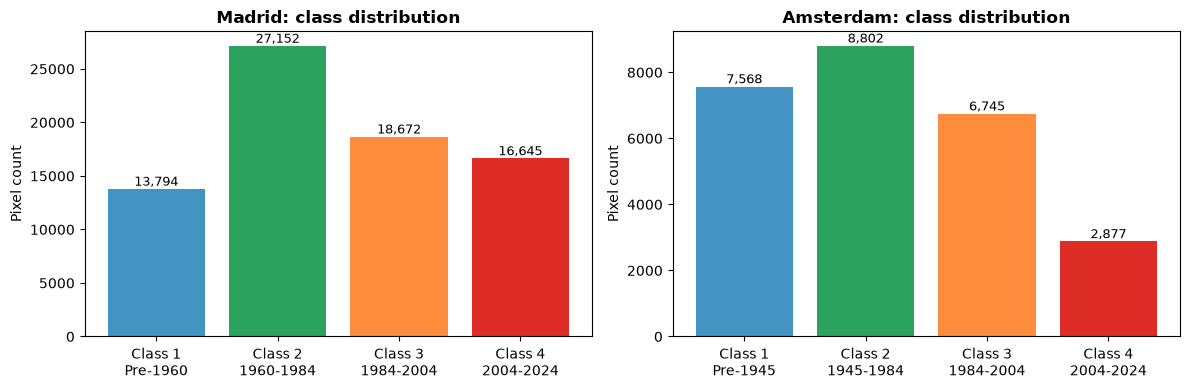

In [8]:
# ── Class distribution per city ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, feat) in zip(axes, [('Madrid', features_madrid),
                                    ('Amsterdam', features_amsterdam)]):
    labels = CLASS_LABELS[name]
    classes = [1, 2, 3, 4]
    counts  = [(feat['age_class'] == c).sum() for c in classes]
    xlbls   = [f'Class {c}\n{labels[c]}' for c in classes]
    bars    = ax.bar(xlbls, counts, color=[CLASS_COLORS[c] for c in classes], edgecolor='none')
    for bar, n in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
                f'{n:,}', ha='center', va='bottom', fontsize=9)
    ax.set_ylabel('Pixel count')
    ax.set_title(f'{name}: class distribution', fontweight='bold')
plt.tight_layout()
plt.show()


---

## 3.7 Standardisation

After time-series gap filling, no NaN values remain in the feature matrix — every pixel
has a value for every year and therefore defined early-, late-, and YOY-period statistics.

`StandardScaler` normalises each feature to zero mean and unit variance. This matters
for the k-NN and prototype classifiers used in Notebook 4, where distances depend on
scale. It is fit on Madrid only and applied to Amsterdam, maintaining the correct protocol
for cross-city transfer.

In [ ]:
TARGET_COL = 'age_class'

X_madrid    = features_madrid[FEATURE_COLS].values.astype(np.float64)
y_madrid    = features_madrid[TARGET_COL].values.astype(int)
X_amsterdam = features_amsterdam[FEATURE_COLS].values.astype(np.float64)
y_amsterdam = features_amsterdam[TARGET_COL].values.astype(int)

# Sanity check
for name, X in [('Madrid', X_madrid), ('Amsterdam', X_amsterdam)]:
    n_nan = np.isnan(X).any(axis=1).sum()
    status = 'OK' if n_nan == 0 else f'WARNING: {n_nan} pixels with NaN'
    print(f'{name}: {X.shape}  NaN check: {status}')

scaler = StandardScaler()
X_madrid    = scaler.fit_transform(X_madrid)
X_amsterdam = scaler.transform(X_amsterdam)
print('Standardised.')


---

## 3.8 Save Preprocessed Data

The preprocessed arrays are saved so Notebook 4 can load them directly without repeating
these steps.

In [ ]:
import pickle
from pathlib import Path

output_dir = Path('data/preprocessed')
output_dir.mkdir(exist_ok=True)

data = {
    'X_madrid':            X_madrid,
    'y_madrid':            y_madrid,
    'X_amsterdam':         X_amsterdam,
    'y_amsterdam':         y_amsterdam,
    'feature_names':       FEATURE_COLS,
    'scaler':              scaler,
    'pixel_ids_madrid':    features_madrid[['px_key', 'py_key']].values,
    'pixel_ids_amsterdam': features_amsterdam[['px_key', 'py_key']].values,
    'feat_groups': {
        'overall':    FEAT_OVERALL,
        'indices':    FEAT_INDICES,
        'early':      FEAT_EARLY,
        'late':       FEAT_LATE,
        'yoy':        FEAT_YOY,
        'indicators': FEAT_IND,
        'deltas':      FEAT_DELTA,
        'interactions': FEAT_INTER,
        'coverage':    FEAT_COVER,
        'regional':    FEAT_REG,
    },
}

save_path = output_dir / 'preprocessed_data.pkl'
with open(save_path, 'wb') as f:
    pickle.dump(data, f)

size_mb = save_path.stat().st_size / 1024 / 1024
print(f'Saved to: {save_path}  ({size_mb:.1f} MB)')


---

## 3.9 Summary

In this notebook we:

1. **Loaded** `madrid_train.parquet` (training city) and `amsterdam_data.parquet` (transfer target)
2. **Assigned age classes** from `weighted_mean_year` using city-specific boundaries
3. **Flattened** the wide-format data to one best QA-valid observation per pixel-year,
   removing haze-contaminated rows (Blue > 15,000); `row`, `col` and `coverage` are now
   carried through for regional features
4. **Recorded period coverage** — `has_early_data` and `has_late_data` binary indicators
   computed from the original observed years before any gap-filling
5. **Filled time-series gaps** by linear interpolation between observed years; edge values
   (before first obs / after last obs) are set to the nearest observed value
6. **Computed 14 spectral indices & band-algebra terms** (5 original + NBR, NDWI, EVI, SAVI,
   three tasseled-cap combinations, two band ratios) on the gap-filled series
7. **Aggregated to one row per pixel** using temporal statistics:
   - Overall mean/std for all bands and indices (40 features)
   - Early-period (1984-2003) and late-period (2004+) mean/std, bands + indices (80 features)
   - Year-on-year change mean/std (12 features)
   - Early→late deltas and percent changes (40 features)
   - Spectral interaction terms `NDBI-NDVI`, `UI-MNDWI`, guarded ratios (4 features)
   - Building `coverage` (1 feature) and period-coverage indicators (2 features)
8. **Added regional features** on the 30 m grid (94 features): 3×3 neighbourhood count,
   neighbour mean/std and own−neighbour contrast; 600 m and 1.5 km tile mean/std,
   own−tile deviation and tile counts — labels are never aggregated
9. **Standardised** using StandardScaler fit on Madrid only
10. **Saved** the preprocessed arrays (`data/preprocessed/preprocessed_data.pkl`), including
    the per-group feature lists, so Notebook 4 can load them directly

**Total: 273 features per pixel** (was 60 in the original pipeline).

In [ ]:
print("Madrid:", X_madrid.shape, y_madrid.shape)
print("Amsterdam:", X_amsterdam.shape, y_amsterdam.shape)
print("Madrid classes:", np.unique(y_madrid, return_counts=True))